# TCC: Previsão de Inadimplência em Concessão de Crédito
**Metodologia:** CRISP-DM

---

## Fases 4 e 5: Modelagem Preditiva e Avaliação (*Modeling & Evaluation*)

Este *notebook* dá continuidade à metodologia CRISP-DM. Após o entendimento e a preparação matemática dos dados (Fases 1, 2 e 3) realizados nos arquivos anteriores, o foco agora é treinar os algoritmos de *Machine Learning* e avaliar o seu desempenho.

Com base na fundamentação do projeto, aplicaremos o **Aprendizado Sensível ao Custo** (*Cost-Sensitive Learning*) para lidar com o desbalanceamento da classe alvo (80% adimplentes / 20% inadimplentes). Iniciaremos com a Regressão Logística para estabelecer a nossa linha de base (*baseline*) e avançaremos para os métodos baseados em árvores (Random Forest e XGBoost).

---

## 1. Importação de Bibliotecas e Carregamento dos Dados
Nesta etapa inicial, carregamos as ferramentas matemáticas do Scikit-Learn e as matrizes otimizadas em Parquet (Treino, Validação e Teste) geradas ao final da etapa de Preparação de Dados.

In [4]:
# Importacao das bibliotecas de modelagem preditiva e metricas
import polars as pl
import pandas as pd
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    average_precision_score # PR-AUC
)

# Importacao das bibliotecas visuais para a Matriz de Confusao
import matplotlib.pyplot as plt
import seaborn as sns

# FUNCAO PADRONIZADA DE AVALIACAO
def evaluate_classification(y_true, y_pred, y_pred_proba, model_name="Modelo"):
    """Calcula, exibe e retorna as metricas de classificacao."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    pr_auc = average_precision_score(y_true, y_pred_proba)

    print(f"--- Resultados: {model_name} ---")
    print(f"PR-AUC  : {pr_auc:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Recall  : {rec:.4f}")
    print(f"Precisao: {prec:.4f}")
    print(f"Acuracia: {acc:.4f}\n")
    
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Adimplente (0)', 'Inadimplente (1)'], 
                yticklabels=['Adimplente (0)', 'Inadimplente (1)'])
    plt.ylabel('Classe Real (Actual value)')
    plt.xlabel('Classe Predita (Predicted value)')
    plt.title(f'Matriz de Confusao - {model_name}')
    plt.show()

    return {
        "Modelo": model_name,
        "PR-AUC": pr_auc,
        "F1-score": f1,
        "Recall": rec,
        "Precisao": prec,
        "Acuracia": acc,
    }

# PREPARACAO DOS DADOS
# Carregamento otimizado dos ficheiros particionados
df_train = pl.read_parquet('DataSet_Loan/df_treino.parquet')
df_val = pl.read_parquet('DataSet_Loan/df_val.parquet')
df_test = pl.read_parquet('DataSet_Loan/df_teste.parquet')

# Separacao entre variaveis preditivas (X) e a variavel alvo (y)
X_train = df_train.drop('target').to_pandas()
y_train = df_train.select('target').to_pandas().squeeze()

X_val = df_val.drop('target').to_pandas()
y_val = df_val.select('target').to_pandas().squeeze()

X_test = df_test.drop('target').to_pandas()
y_test = df_test.select('target').to_pandas().squeeze()

Matplotlib is building the font cache; this may take a moment.


## 2. Regressão Logística (*Baseline*)

A **Regressão Logística** é utilizada como modelo de linha de base (*baseline*). Por ser um algoritmo estatístico de natureza linear, seu objetivo é estabelecer um referencial de desempenho para comparação com os modelos de *ensemble learning*.


### 2.1. Treinamento do Modelo

Nesta etapa, o modelo é treinado com o conjunto de treino e avaliado no conjunto de validação. Como a variável alvo apresenta desbalanceamento, utiliza-se `class_weight='balanced'`. As variáveis são padronizadas com `StandardScaler`, pois a Regressão Logística é sensível à escala dos atributos.

--- Resultados: Regressao Logistica - Baseline ---
PR-AUC  : 0.3733
F1-score: 0.4250
Recall  : 0.6556
Precisao: 0.3144
Acuracia: 0.6489



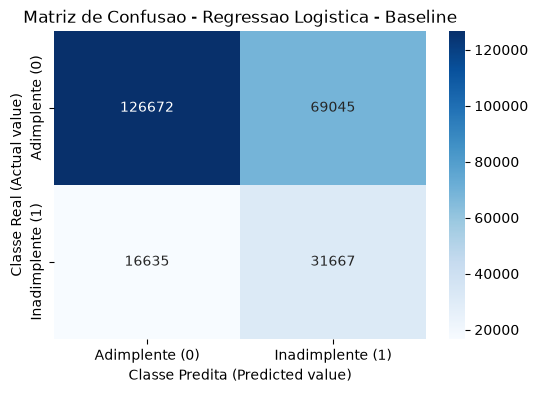

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=42, max_iter=2000)
)

log_reg.fit(X_train, y_train)

y_pred_val_lr = log_reg.predict(X_val)
y_pred_proba_val_lr = log_reg.predict_proba(X_val)[:, 1]

baseline_lr_results = evaluate_classification(
    y_val,
    y_pred_val_lr, 
    y_pred_proba_val_lr,
    model_name="Regressao Logistica - Baseline"
)

## 3. Random Forest

Avançando para os modelos de *ensemble learning*, a segunda abordagem avaliada é o algoritmo **Random Forest**. Por ser um método baseado na construção de múltiplas árvores de decisão com menor correlação entre si, utilizando a estratégia de *bagging*, esse modelo possui alta capacidade para mapear relações não lineares complexas entre os atributos dos clientes, algo que o modelo linear de *baseline* não consegue realizar nativamente.

Para manter a coerência metodológica e lidar com o desbalanceamento das classes, a técnica de **Cost-Sensitive Learning** é preservada por meio do parâmetro `class_weight='balanced'`. Além disso, para mitigar o risco de sobreajuste (*overfitting*) inerente aos modelos baseados em árvores, a profundidade máxima das árvores (`max_depth`) é inicialmente controlada.

Ao contrário da Regressão Logística, algoritmos baseados em árvores não dependem da escala das variáveis. Por isso, o Random Forest dispensa o uso de padronizadores como o `StandardScaler`.

### 3.1. Treinamento do Modelo

Nesta etapa, é treinada uma configuração inicial do Random Forest utilizando o conjunto de treino. O modelo é avaliado no conjunto de validação, que será utilizado como referência para as etapas posteriores de ajuste.

--- Resultados: Random Forest - Baseline ---
PR-AUC  : 0.3780
F1-score: 0.4256
Recall  : 0.6769
Precisao: 0.3104
Acuracia: 0.6383



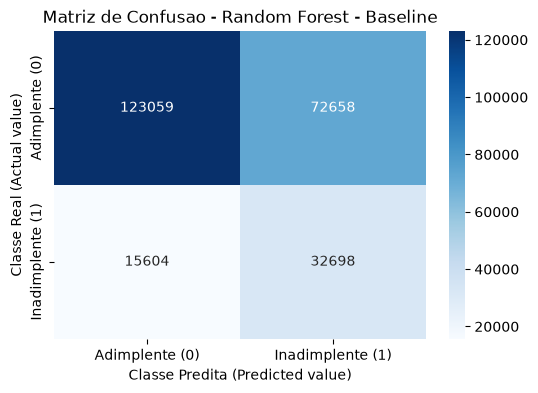

In [9]:
from sklearn.ensemble import RandomForestClassifier

# max_depth=10 atua como controle inicial contra overfitting (sobreajuste)
# n_jobs=-1 paraleliza o processamento para maior velocidade
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Treinamento
rf_model.fit(X_train, y_train)

# Geração das predições e probabilidades no conjunto de validação
y_pred_val_rf = rf_model.predict(X_val)
y_pred_proba_val_rf = rf_model.predict_proba(X_val)[:, 1]

# Registro automatico dos parametros do baseline
baseline_rf_params = {
    parametro: rf_model.get_params()[parametro]
    for parametro in [
        "n_estimators", 
        "max_depth", 
        "class_weight", 
        "random_state"
    ]
}

baseline_rf_results = evaluate_classification(
    y_val,
    y_pred_val_rf,
    y_pred_proba_val_rf,
    model_name="Random Forest - Baseline"
)

### 3.2. Ajuste de Hiperparâmetros

Após a avaliação da configuração inicial, os principais hiperparâmetros do Random Forest serão ajustados de forma automatizada utilizando os conjuntos de treino e validação. Serão avaliados diferentes valores de `n_estimators`, `max_depth` e `min_samples_leaf`, que controlam, respectivamente, a quantidade de árvores, a complexidade máxima de cada árvore e o número mínimo de observações em cada folha.

A escolha da configuração final será orientada principalmente pelas métricas PR-AUC, Recall e F1-score, considerando o objetivo de identificar clientes com maior risco de inadimplência. O conjunto de teste Out-of-Time não participa dessa etapa.

In [4]:
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, f1_score, recall_score

param_grid_rf = {
    "n_estimators": [100, 300],
    "max_depth": [10, 12],
    "min_samples_leaf": [5, 15, 30],
}

rf_tuning_results = []

for params in ParameterGrid(param_grid_rf):
    model = RandomForestClassifier(
        **params,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    rf_tuning_results.append({
        **params,
        "PR-AUC": average_precision_score(y_val, y_proba),
        "F1-score": f1_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
    })

rf_tuning_results_df = (
    pd.DataFrame(rf_tuning_results)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

rf_tuning_results_df

,max_depth,min_samples_leaf,n_estimators,PR-AUC,F1-score,Recall
0,12,30,300,0.380115,0.427460,0.669558
1,12,30,100,0.379890,0.427147,0.669289
2,12,15,300,0.379864,0.427827,0.668689
3,12,5,300,0.379730,0.427772,0.667757
4,12,15,100,0.379599,0.427396,0.668254
5,12,5,100,0.379356,0.427314,0.665004
6,10,30,300,0.378287,0.425685,0.676618
7,10,30,100,0.378205,0.426169,0.675790
8,10,15,300,0.378156,0.425537,0.676183
9,10,5,300,0.378107,0.425661,0.675997


### 3.3. Treinamento da Melhor Configuração

Após a comparação das configurações testadas, a combinação com maior PR-AUC na validação é selecionada para compor o Random Forest ajustado. Em seguida, o modelo é treinado novamente com os parâmetros escolhidos e avaliado no conjunto de validação.

--- Resultados: Random Forest - Ajustado (sem calibração) ---
PR-AUC  : 0.3801
F1-score: 0.4275
Recall  : 0.6696
Precisao: 0.3139
Acuracia: 0.6450



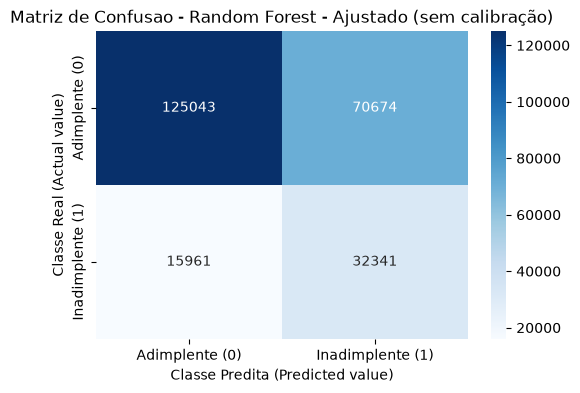

--- Resultados: Random Forest - Ajustado (calibrado, limiar 0.5) ---
PR-AUC  : 0.3803
F1-score: 0.1144
Recall  : 0.0635
Precisao: 0.5715
Acuracia: 0.8052



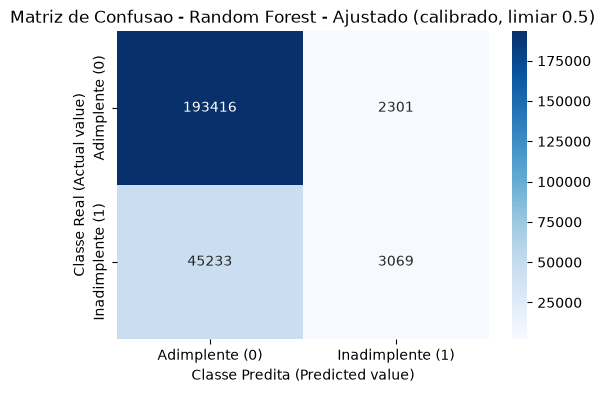

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV

rf_tuned_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=30,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

rf_tuned_model.fit(X_train, y_train)

y_pred_val_rf_tuned = rf_tuned_model.predict(X_val)
y_pred_proba_val_rf_tuned = rf_tuned_model.predict_proba(X_val)[:, 1]

rf_tuned_results = evaluate_classification(
    y_val,
    y_pred_val_rf_tuned,
    y_pred_proba_val_rf_tuned,
    model_name="Random Forest - Ajustado (sem calibração)",
)

rf_calibrator = CalibratedClassifierCV(
    estimator=rf_tuned_model, method='sigmoid', cv=5
)
rf_calibrator.fit(X_train, y_train)

y_pred_val_rf_calibrated = rf_calibrator.predict(X_val)
y_pred_proba_val_rf_calibrated = rf_calibrator.predict_proba(X_val)[:, 1]

rf_tuned_params = {
    parametro: rf_tuned_model.get_params()[parametro]
    for parametro in [
        "n_estimators",
        "max_depth",
        "min_samples_leaf",
        "class_weight",
        "random_state",
    ]
}

rf_calibrated_results = evaluate_classification(
    y_val,
    y_pred_val_rf_calibrated,
    y_pred_proba_val_rf_calibrated,
    model_name="Random Forest - Ajustado (calibrado, limiar 0.5)",
)

## 4. XGBoost

O XGBoost é um algoritmo de *ensemble learning* baseado no treinamento sequencial de árvores de decisão. A cada etapa, o modelo busca corrigir os erros cometidos pelas árvores anteriores, permitindo representar relações não lineares complexas.

Assim como nos modelos anteriores, o XGBoost será treinado com os dados de treino e avaliado na validação. Para lidar com o desbalanceamento da variável alvo, será utilizado `scale_pos_weight`, calculado a partir da proporção entre as classes do conjunto de treino.

### 4.1. Treinamento do Modelo

Nesta etapa, é treinada uma configuração inicial do XGBoost utilizando o conjunto de treino. O modelo é avaliado no conjunto de validação, que será utilizado como referência para as etapas posteriores de ajuste.

--- Resultados: XGBoost - Baseline ---
PR-AUC  : 0.3832
F1-score: 0.4294
Recall  : 0.6740
Precisao: 0.3151
Acuracia: 0.6454



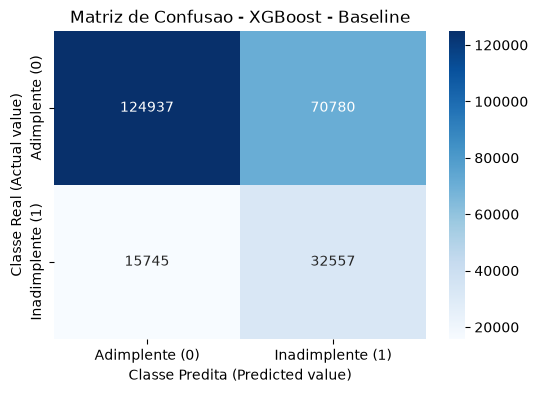

In [5]:
from xgboost import XGBClassifier

# Calcula o peso da classe de inadimplentes
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

y_pred_val_xgb = xgb_model.predict(X_val)
y_pred_proba_val_xgb = xgb_model.predict_proba(X_val)[:, 1]

xgb_params = {
    parametro: xgb_model.get_params()[parametro]
    for parametro in [
        "n_estimators",
        "max_depth",
        "learning_rate",
        "scale_pos_weight",
        "random_state",
    ]
}

baseline_xgb_results = evaluate_classification(
    y_val,
    y_pred_val_xgb,
    y_pred_proba_val_xgb,
    model_name="XGBoost - Baseline",
)

### 4.2. Ajuste de Hiperparâmetros

Após o treinamento inicial, serão testadas algumas combinações de `n_estimators`, `max_depth` e `learning_rate`. A comparação será feita no conjunto de validação, priorizando PR-AUC, F1-score e Recall. O conjunto OOT será utilizado somente na avaliação final.

In [8]:
from xgboost import XGBClassifier
from sklearn.model_selection import ParameterGrid

xgb_param_grid = {
    "n_estimators": [400, 600],
    "max_depth": [4, 6],           
    "learning_rate": [0.05, 0.1, 0.2]      
}

xgb_tuning_results = []

for params in ParameterGrid(xgb_param_grid):
    model = XGBClassifier(
        **params,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    xgb_tuning_results.append({
        **params,
        "PR-AUC": average_precision_score(y_val, y_proba),
        "F1-score": f1_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
    })

xgb_tuning_results_df = (
    pd.DataFrame(xgb_tuning_results)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

xgb_tuning_results_df

,learning_rate,max_depth,n_estimators,PR-AUC,F1-score,Recall
0,0.05,6,600,0.386527,0.432928,0.671629
1,0.10,4,600,0.386074,0.432374,0.673512
2,0.05,6,400,0.385924,0.432374,0.674051
3,0.10,6,400,0.385655,0.431641,0.666867
4,0.10,4,400,0.385290,0.431549,0.674051
5,0.10,6,600,0.385210,0.432040,0.664258
6,0.20,4,400,0.385084,0.432055,0.673119
7,0.05,4,600,0.385026,0.431685,0.675210
8,0.20,4,600,0.384880,0.431913,0.670179
9,0.05,4,400,0.383792,0.430712,0.674651


### 4.3. Treinamento da Melhor Configuração

A configuração com maior PR-AUC na validação será utilizada para treinar o XGBoost ajustado. O modelo será avaliado novamente na validação antes da comparação final com os demais algoritmos.

--- Resultados: XGBoost - Ajustado (sem calibração) ---
PR-AUC  : 0.3851
F1-score: 0.4320
Recall  : 0.6710
Precisao: 0.3185
Acuracia: 0.6507



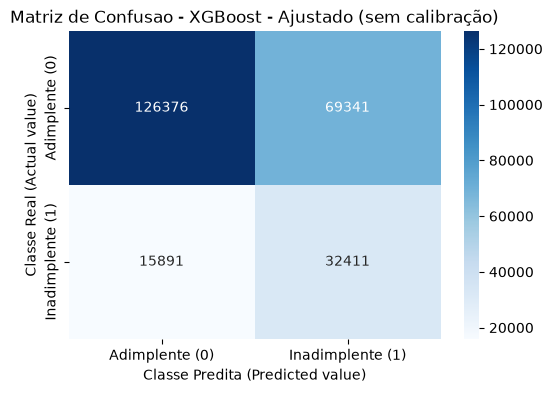

--- Resultados: XGBoost - Ajustado (calibrado, limiar 0.5) ---
PR-AUC  : 0.3860
F1-score: 0.1210
Recall  : 0.0676
Precisao: 0.5801
Acuracia: 0.8057



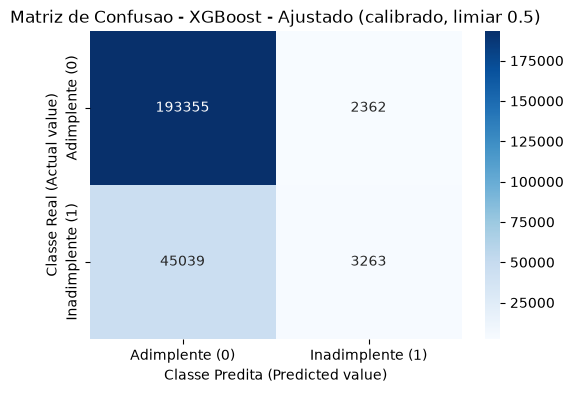

In [ ]:
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV

xgb_tuned_model = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)

xgb_tuned_model.fit(X_train, y_train)

y_pred_val_xgb_tuned = xgb_tuned_model.predict(X_val)
y_pred_proba_val_xgb_tuned = xgb_tuned_model.predict_proba(X_val)[:, 1]

xgb_tuned_results = evaluate_classification(
    y_val,
    y_pred_val_xgb_tuned,
    y_pred_proba_val_xgb_tuned,
    model_name="XGBoost - Ajustado (sem calibração)",
)

xgb_calibrator = CalibratedClassifierCV(
    estimator=xgb_tuned_model, method='sigmoid', cv=5
)
xgb_calibrator.fit(X_train, y_train)

y_pred_val_xgb_calibrated = xgb_calibrator.predict(X_val)
y_pred_proba_val_xgb_calibrated = xgb_calibrator.predict_proba(X_val)[:, 1]

xgb_tuned_params = {
    parametro: xgb_tuned_model.get_params()[parametro]
    for parametro in [
        "n_estimators",
        "max_depth",
        "learning_rate",
        "scale_pos_weight",
        "random_state",
    ]
}

xgb_calibrated_results = evaluate_classification(
    y_val,
    y_pred_val_xgb_calibrated,
    y_pred_proba_val_xgb_calibrated,
    model_name="XGBoost - Ajustado (calibrado, limiar 0.5)",
)

## 5. Registro e Comparação dos Modelos

Nesta etapa, são reunidos os resultados obtidos pelos modelos durante o desenvolvimento, utilizando exclusivamente o conjunto de validação. O objetivo é comparar o desempenho da Regressão Logística, utilizada como modelo baseline, com as versões inicial e ajustada do Random Forest e do XGBoost.

As métricas consideradas são PR-AUC, F1-score, Recall, precisão e acurácia. Essa comparação orienta a seleção dos modelos que serão submetidos à avaliação final no conjunto de teste Out-of-Time (OOT).

O conjunto OOT permanece isolado nesta etapa e não é utilizado para escolher modelos ou hiperparâmetros.

In [11]:
# Comparacao dos resultados obtidos no conjunto de validacao
comparison = pd.DataFrame([
    baseline_lr_results,
    baseline_rf_results,
    rf_tuned_results,
    rf_calibrated_results,
    baseline_xgb_results,
    xgb_tuned_results,
    xgb_calibrated_results
])

comparison

,Modelo,PR-AUC,F1-score,Recall,Precisao,Acuracia
0,Regressao Logistica - Baseline,0.373281,0.425020,0.655604,0.314431,0.648880
1,Random Forest - Baseline,0.378000,0.425595,0.676949,0.310357,0.638299
2,Random Forest - Ajustado (sem calibração),0.380115,0.427460,0.669558,0.313945,0.644966
3,"Random Forest - Ajustado (calibrado, limiar 0.5)",0.380296,0.114361,0.063538,0.571508,0.805204
4,XGBoost - Baseline,0.383196,0.429401,0.674030,0.315057,0.645417
5,XGBoost - Ajustado (sem calibração),0.385102,0.431991,0.671007,0.318529,0.650716
6,"XGBoost - Ajustado (calibrado, limiar 0.5)",0.385954,0.121015,0.067554,0.580089,0.805749


## 6. Calibração do Limiar de Decisão

Com os modelos ajustados, o limiar de decisão ótimo é calibrado exclusivamente
no conjunto de validação, mantendo o conjunto *Out-of-Time* completamente isolado
para a avaliação final.

Pela teoria de *Cost-Sensitive Learning* de Elkan (2001), o limiar ótimo $p^*$
é definido como:

$$p^* = \frac{C_{FP}}{C_{FP} + C_{FN}}$$

A tabela abaixo apresenta os resultados para cada limiar testado. O limiar
selecionado será aquele que melhor equilibra Recall e F1-score no contexto
de predição de inadimplência.

In [11]:
import numpy as np
from sklearn.metrics import f1_score, recall_score, precision_score
import pandas as pd

# Testa de 0.10 até 0.60, andando de 0.02 em 0.02 (gera 26 limiares para cada modelo)
thresholds = np.arange(0.10, 0.62, 0.02)

modelos_val = {
    "Regressão Logística": y_pred_proba_val_lr,
    "Random Forest":       y_pred_proba_val_rf_tuned,
    "XGBoost":             y_pred_proba_val_xgb_tuned,
}

calibration_results = []

for model_name, y_proba in modelos_val.items():
    for t in thresholds:
        y_pred_custom = (y_proba >= t).astype(int)
        calibration_results.append({
            "Modelo":    model_name,
            "Limiar":    round(t, 2), # Arredonda o limiar para não dar bug flutuante
            "F1-score":  round(f1_score(y_val, y_pred_custom), 4),
            "Recall":    round(recall_score(y_val, y_pred_custom), 4),
            "Precisão":  round(precision_score(y_val, y_pred_custom), 4),
        })

calibration_df = (
    pd.DataFrame(calibration_results)
    # Ordena pelo melhor F1-score para os melhores subirem primeiro!
    .sort_values(["Modelo", "F1-score"], ascending=[True, False])
    .reset_index(drop=True)
)

# Agrupa por modelo e pega apenas as 3 primeiras linhas (os 3 melhores limiares)
top_3_por_modelo = calibration_df.groupby("Modelo").head(3).reset_index(drop=True)

print("=== Top 3 Melhores Limiares por Modelo (Conjunto de Validação) ===")
display(top_3_por_modelo)


=== Top 3 Melhores Limiares por Modelo (Conjunto de Validação) ===


,Modelo,Limiar,F1-score,Recall,Precisão
0,Random Forest,0.22,0.4293,0.6136,0.3301
1,Random Forest,0.20,0.4278,0.6677,0.3147
2,Random Forest,0.24,0.4261,0.5572,0.3449
3,Regressão Logística,0.52,0.4256,0.6171,0.3248
4,Regressão Logística,0.50,0.4250,0.6556,0.3144
5,Regressão Logística,0.48,0.4237,0.6939,0.3049
6,XGBoost,0.22,0.4339,0.6181,0.3343
7,XGBoost,0.20,0.4327,0.6697,0.3196
8,XGBoost,0.24,0.4324,0.5672,0.3494


## 7. Avaliação Final na Base de Teste (Out-of-Time)

A etapa final deste estudo consiste na submissão dos modelos treinados à base de teste Out-of-Time (OOT). Esta base contém registros cronologicamente posteriores aos dados de treino e validação, simulando com fidelidade o cenário de implantação em produção.

O objetivo é testar a capacidade de generalização dos algoritmos perante dados inéditos e verificar a estabilidade das métricas (especialmente a PR-AUC) contra o desgaste natural ao longo do tempo.


In [12]:
# Extrai o melhor limiar de cada modelo para usar no OOT
best_thresholds = (
    calibration_df
    .groupby("Modelo")
    .first()  # já está ordenado por F1 descrescente, então o primeiro é o melhor
    .reset_index()[["Modelo", "Limiar"]]
)

BEST_LR_THRESHOLD  = best_thresholds.loc[best_thresholds["Modelo"] == "Regressão Logística", "Limiar"].values[0]
BEST_RF_THRESHOLD  = best_thresholds.loc[best_thresholds["Modelo"] == "Random Forest", "Limiar"].values[0]
BEST_XGB_THRESHOLD = best_thresholds.loc[best_thresholds["Modelo"] == "XGBoost", "Limiar"].values[0]

print(f"Limiar RL:  {BEST_LR_THRESHOLD}")
print(f"Limiar RF:  {BEST_RF_THRESHOLD}")
print(f"Limiar XGB: {BEST_XGB_THRESHOLD}")

Limiar RL:  0.52
Limiar RF:  0.22
Limiar XGB: 0.22


### 7.1 Regressao Logistica (Baseline)

Avaliação do modelo estatístico linear que serve como piso de referência metodológica do projeto.

--- Resultados: OOT: Regressao Logistica - Baseline ---
PR-AUC  : 0.3392
F1-score: 0.4102
Recall  : 0.6122
Precisao: 0.3084
Acuracia: 0.6636



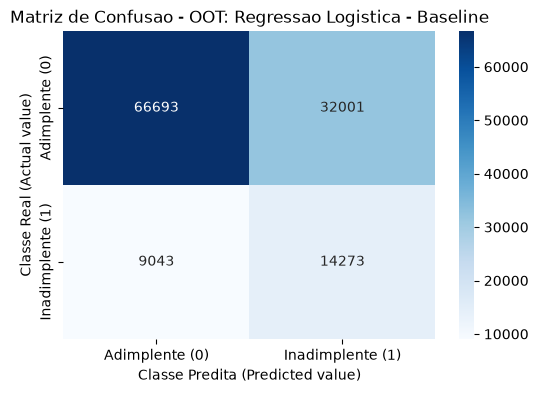

In [13]:
# Regressão Logística com limiar calibrado
y_pred_proba_test_lr = log_reg.predict_proba(X_test)[:, 1]
y_pred_test_lr = (y_pred_proba_test_lr >= BEST_LR_THRESHOLD).astype(int)

lr_test_results = evaluate_classification(
    y_test,
    y_pred_test_lr,
    y_pred_proba_test_lr,
    model_name="OOT: Regressao Logistica - Baseline"
)

### 7.2 Random Forest (Ajustado)

Avaliação do modelo baseado em árvores independentes, utilizando os melhores hiperparâmetros definidos durante a etapa de validação.

--- Resultados: OOT: Random Forest - Ajustado ---
PR-AUC  : 0.3504
F1-score: 0.4158
Recall  : 0.6106
Precisao: 0.3152
Acuracia: 0.6721



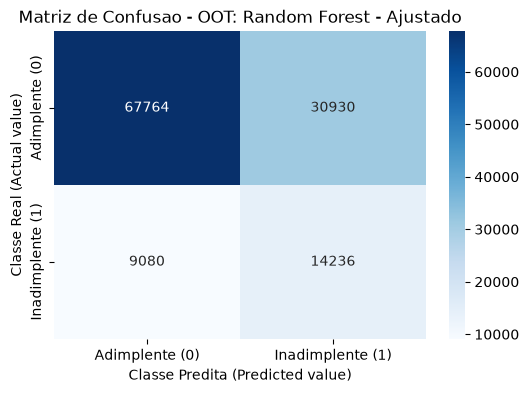

In [14]:
# Random Forest com limiar calibrado
y_pred_proba_test_rf = rf_calibrator.predict_proba(X_test)[:, 1]
y_pred_test_rf = (y_pred_proba_test_rf >= BEST_RF_THRESHOLD).astype(int)

rf_test_results = evaluate_classification(
    y_test,
    y_pred_test_rf,
    y_pred_proba_test_rf,
    model_name="OOT: Random Forest - Ajustado"
)

### 7.3 XGBoost (Ajustado)

Avaliação do modelo baseado em árvores sequenciais, utilizando os melhores hiperparâmetros definidos durante a etapa de validação.

--- Resultados: OOT: XGBoost - Ajustado ---
PR-AUC  : 0.3591
F1-score: 0.4227
Recall  : 0.6344
Precisao: 0.3169
Acuracia: 0.6688



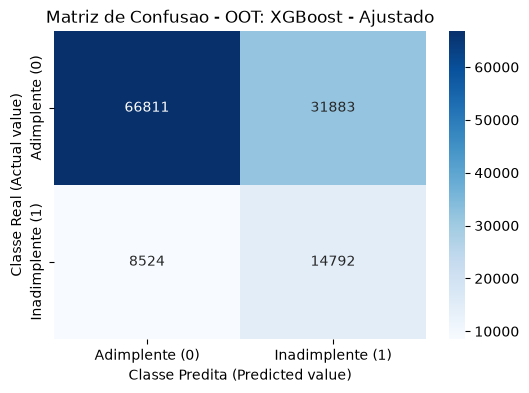

In [15]:
# XGBoost com limiar calibrado
y_pred_proba_test_xgb = xgb_calibrator.predict_proba(X_test)[:, 1]
y_pred_test_xgb = (y_pred_proba_test_xgb >= BEST_XGB_THRESHOLD).astype(int)

xgb_test_results = evaluate_classification(
    y_test,
    y_pred_test_xgb,
    y_pred_proba_test_xgb,
    model_name="OOT: XGBoost - Ajustado"
)

### 7.4 Consolidação e Comparação Final

Com todos os modelos avaliados na base *Out-of-Time*, esta etapa reúne os resultados 
em uma tabela comparativa final. A ordenação é feita pela PR-AUC, métrica central 
deste estudo por ser mais rigorosa em cenários de alto desbalanceamento.

Os resultados refletem o desempenho real de cada algoritmo frente a dados 
cronologicamente posteriores ao período de treinamento, simulando com fidelidade 
o cenário de implantação em produção.

In [16]:
oot_results = [lr_test_results, rf_test_results, xgb_test_results]

oot_results_df = (
    pd.DataFrame(oot_results)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

print("\n=== Resultados Finais na Base de Teste (Out-of-Time) ===")
display(oot_results_df)


=== Resultados Finais na Base de Teste (Out-of-Time) ===


,Modelo,PR-AUC,F1-score,Recall,Precisao,Acuracia
0,OOT: XGBoost - Ajustado,0.359139,0.422683,0.634414,0.316915,0.668822
1,OOT: Random Forest - Ajustado,0.350428,0.415759,0.610568,0.315193,0.672076
2,OOT: Regressao Logistica - Baseline,0.339178,0.410203,0.612155,0.308445,0.663601


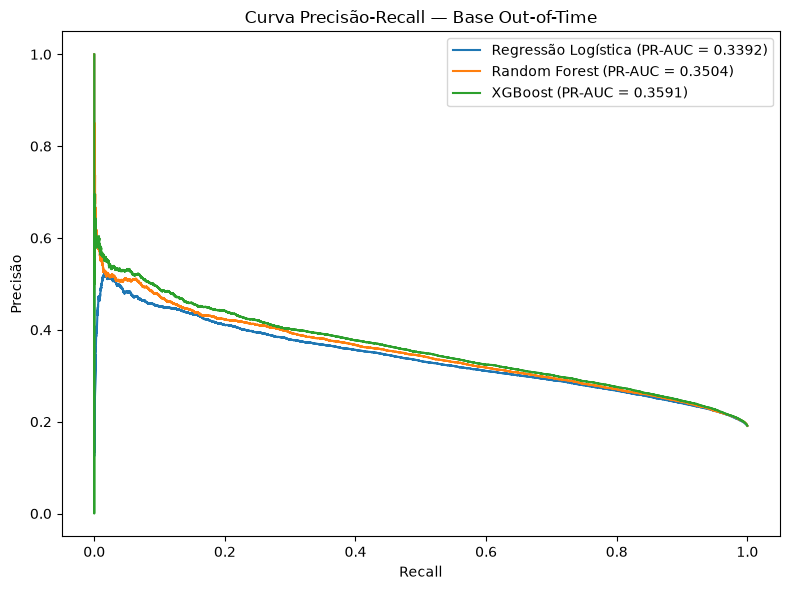

In [17]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for model_name, y_proba in [
    ("Regressão Logística", y_pred_proba_test_lr),
    ("Random Forest", y_pred_proba_test_rf),
    ("XGBoost", y_pred_proba_test_xgb),
]:
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    plt.plot(recall, precision, label=f"{model_name} (PR-AUC = {ap:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title("Curva Precisão-Recall — Base Out-of-Time")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Análise de Ablação - Impacto de int_rate e grade

--- Resultados: OOT: XGBoost - Sem int_rate e grade ---
PR-AUC  : 0.3359
F1-score: 0.3975
Recall  : 0.5381
Precisao: 0.3152
Acuracia: 0.6883



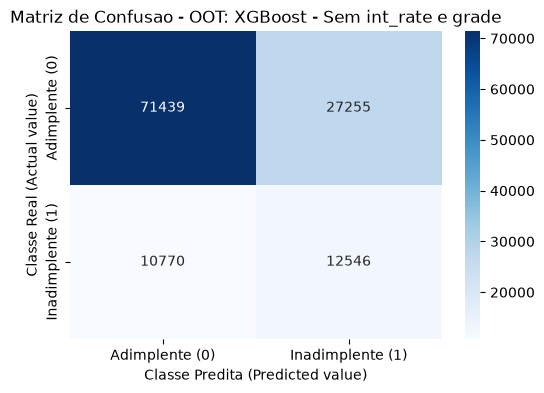

,Modelo,PR-AUC,F1-score,Recall,Precisao,Acuracia
0,OOT: XGBoost - Ajustado,0.359139,0.422683,0.634414,0.316915,0.668822
1,OOT: XGBoost - Sem int_rate e grade,0.335944,0.397547,0.538085,0.315218,0.688345


In [18]:
LEAKAGE_COLS = ['int_rate', 'grade']

X_train_reduced = X_train.drop(columns=LEAKAGE_COLS)
X_val_reduced   = X_val.drop(columns=LEAKAGE_COLS)
X_test_reduced  = X_test.drop(columns=LEAKAGE_COLS)

# Retreina o XGBoost ajustado sem essas variáveis
xgb_reduced = XGBClassifier(
    n_estimators=300,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)

xgb_calibrator_reduced = CalibratedClassifierCV(
    estimator=xgb_reduced, method='sigmoid', cv=5
)
xgb_calibrator_reduced.fit(X_train_reduced, y_train)

y_pred_proba_test_reduced = xgb_calibrator_reduced.predict_proba(X_test_reduced)[:, 1]
y_pred_test_reduced = (y_pred_proba_test_reduced >= BEST_XGB_THRESHOLD).astype(int)

xgb_reduced_results = evaluate_classification(
    y_test,
    y_pred_test_reduced,
    y_pred_proba_test_reduced,
    model_name="OOT: XGBoost - Sem int_rate e grade"
)

# Comparação final
ablation_df = pd.DataFrame([xgb_test_results, xgb_reduced_results])
display(ablation_df)